# PRACTICA EVALUACIÓN FINAL - PARTE II #
Esta segunda parte supone el 25% restante de tarea práctica final del módulo de minería de datos. Junto con la parte 1, ambas puntúan el 60% de la nota final.

En esta parte 2 se pretende evaluar los conceptos relacionados con el analisis de series temporales y su aplicación a modelos de predicción.

Comenzando con esta parte de la práctica, en el primer bloque de código, conviene cargar las librerías que se van a utilizar a lo largo del notebook.

In [1]:
# ============================================================
# IMPORTS
# ============================================================

# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt

# Series temporales - análisis
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

# Series temporales - modelos
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA

En el siguiente paso procedemos a cargar el fichero *Microsoft_Stock.csv* que servirá como conjunto de datos para llevar a cabo toda la evaluación de esta parte II. Se trata de un fichero en el que cada registro contiene para un día concreto datos de apertura, cierre, máximo, mínimo y volumen de cotización de las acciones de Microsoft en la bolsa de Nueva York. Se trata por tanto de un clásico problema de predicción de valores futuros. 

In [2]:
# Cargar el fichero de datos en un DataFrame
df = pd.read_csv('Microsoft_Stock.csv')


En los siguientes bloques de código el alumno debe programar las sentencias de código que considere oportunas para hacerse una idea general de los datos y de las variables. Visualización de datos, gráficos, etc. Los bloques son orientativos, el alumno puede añadir cuantos considere y codificarlos según su criterio.

In [3]:
# Mostrar los 10 primeros registros
print(df.head(10))

                 Date   Open   High    Low  Close    Volume
0   4/1/2015 16:00:00  40.60  40.76  40.31  40.72  36865322
1   4/2/2015 16:00:00  40.66  40.74  40.12  40.29  37487476
2   4/6/2015 16:00:00  40.34  41.78  40.18  41.55  39223692
3   4/7/2015 16:00:00  41.61  41.91  41.31  41.53  28809375
4   4/8/2015 16:00:00  41.48  41.69  41.04  41.42  24753438
5   4/9/2015 16:00:00  41.25  41.62  41.25  41.48  25723861
6  4/10/2015 16:00:00  41.63  41.95  41.41  41.72  28022002
7  4/13/2015 16:00:00  41.40  42.06  41.39  41.76  30276692
8  4/14/2015 16:00:00  41.80  42.03  41.39  41.65  24244382
9  4/15/2015 16:00:00  41.76  42.46  41.68  42.26  27343581


In [4]:
# Describir el DataFrame
print("\n", df.describe())



               Open         High          Low        Close        Volume
count  1511.000000  1511.000000  1511.000000  1511.000000  1.511000e+03
mean    107.385976   108.437472   106.294533   107.422091  3.019863e+07
std      56.691333    57.382276    55.977155    56.702299  1.425266e+07
min      40.340000    40.740000    39.720000    40.290000  1.016120e+05
25%      57.860000    58.060000    57.420000    57.855000  2.136213e+07
50%      93.990000    95.100000    92.920000    93.860000  2.662962e+07
75%     139.440000   140.325000   137.825000   138.965000  3.431962e+07
max     245.030000   246.130000   242.920000   244.990000  1.352271e+08


In [5]:
# Mostrar las columnas y tipos de datos
print("\n", df.dtypes)


 Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


In [6]:
# Dimensiones
print("\nDimensiones:", df.shape)


Dimensiones: (1511, 6)


In [7]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')

print(df.dtypes)
print("\nRango de fechas:", df.index.min(), "->", df.index.max())

Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

Rango de fechas: 2015-04-01 16:00:00 -> 2021-03-31 16:00:00


Se ha de filtrar la serie quedandose solo con los datos desde el año 2020 (incluido) en adelante. Una vez filtrada, mostrar la serie temporal de la variable ***Close*** en un gráfico de línea.

In [8]:
# Filtrar datos desde 2020
df_2020 = df[df.index.year >= 2020]

print("Registros desde 2020:", len(df_2020))
print("Rango filtrado:", df_2020.index.min(), "->", df_2020.index.max())

Registros desde 2020: 314
Rango filtrado: 2020-01-02 16:00:00 -> 2021-03-31 16:00:00


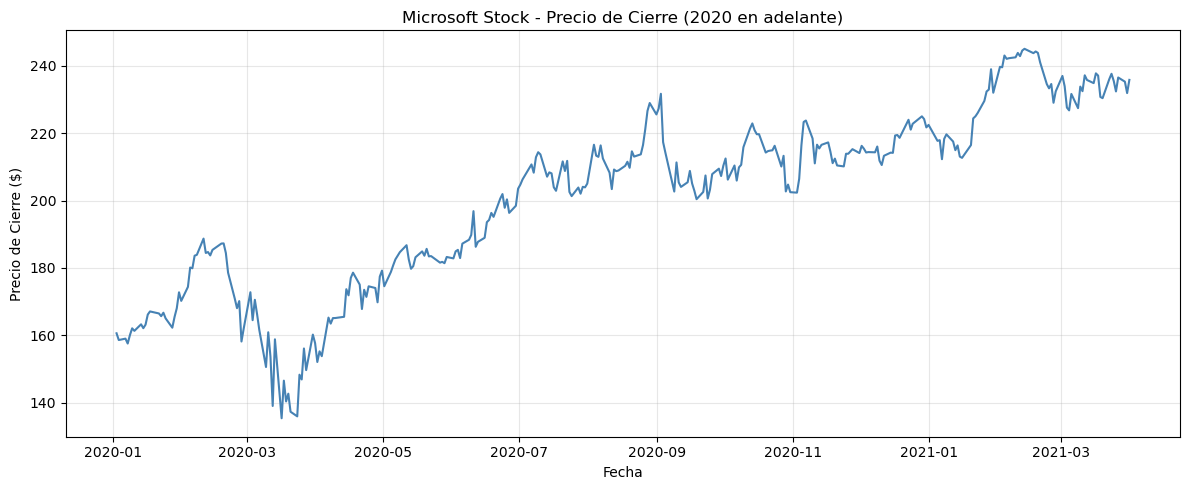

In [9]:
# Gráfico de la serie Close

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_2020.index, df_2020['Close'], color='steelblue', linewidth=1.5)
ax.set_title('Microsoft Stock - Precio de Cierre (2020 en adelante)')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de Cierre ($)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pregunta 1 ###
En primera instancia echando un vistazo a la serie en la gráfica, ¿Qué pinta tiene la serie en cuanto a estacionariedad? Describe brevemente las impresiones acerca de porque parece que la serie es o no estacionaria.

***Respuesta:***

La serie presenta claros signos de no estacionariedad, ya que la media no es constante a lo largo del tiempo (hay tendencia). Como podemos ver se aprecia una caída brusca en marzo 2020 (presumiblemente crash COVID), seguida de una tendencia hacia arriba sostenida que lleva el precio de ~140$ hasta ~240$. Una serie estacionaria debería oscilar alrededor de una media fija.


En conclusión, ni la media ni la varianza son constantes en el tiempo, condiciones necesarias para la estacionariedad.

A continuación pasamos a analizar desde un punto de vista más formal la estacionariedad de la serie. En primer lugar calcular las funciones de autocorrelación y autocorrelación parcial y mostrar las gráficas con ambas funciones.

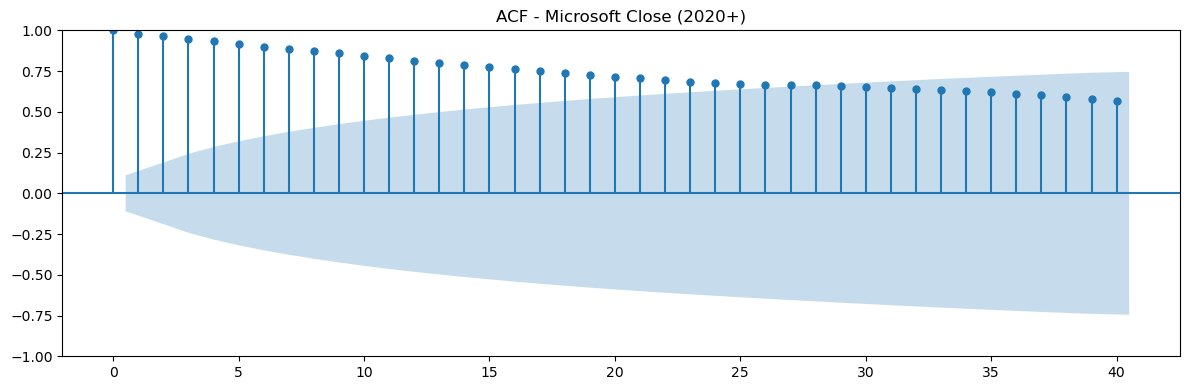

In [10]:
# Gráfica ACF

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df_2020['Close'], lags=40, ax=ax, title='ACF - Microsoft Close (2020+)')
plt.tight_layout()
plt.show()


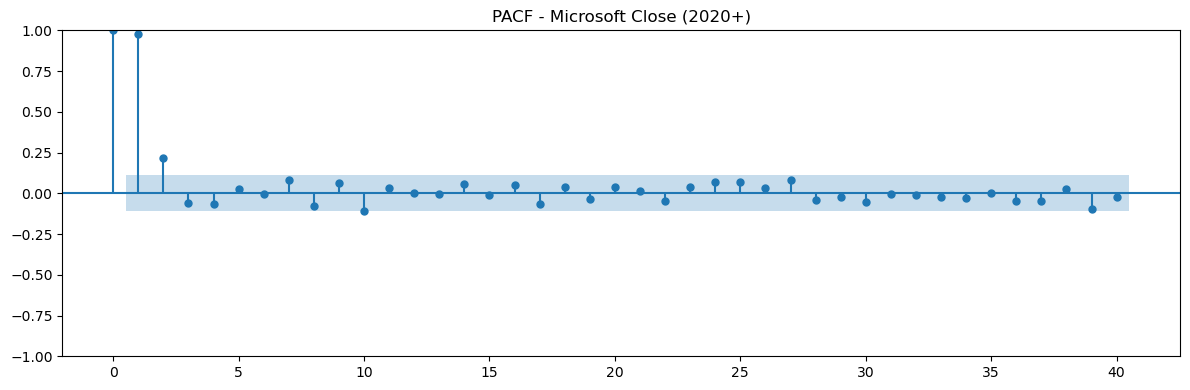

In [11]:
# Gráfica PACF

fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(df_2020['Close'], lags=40, ax=ax, title='PACF - Microsoft Close (2020+)')
plt.tight_layout()
plt.show()

### Pregunta 2 ###
A la vista de las 2 gráficas de autocorrelación, ¿Se aprecian signos de estacionariedad en la serie? ¿Por qué? ¿Se aprecian signos de estacionalidad? ¿Por qué?

***Respuesta:***

No se aprecian signos de estacionariedad. 
La ACF muestra una caída muy lenta y gradual. 
Una serie estacionaria mostraría una ACF que cae rápidamente a cero.

Estacionalidad: tampoco se aprecian signos claros de estacionalidad. Para que hubiera estacionalidad, 
deberíamos ver picos recurrentes en la ACF a intervalos regulares. No se observa ningún patrón de ese tipo.

La PACF refuerza este diagnóstico, ya que hay un pico muy significativo en el lag 1 
y otro menor en el lag 2, cayendo al intervalo de confianza a partir del lag 3.



Ahora mediante un test de Dickey Fuller aumentado, realizamos la última comprobación de estacionariedad de la serie.

In [12]:
# Test de Dickey Fuller Aumentado

resultado_adf = adfuller(df_2020['Close'])

print('ADF Statistic:', resultado_adf[0])
print('p-value:', resultado_adf[1])


ADF Statistic: -1.4029588977517944
p-value: 0.5808567665335327


### Pregunta 3 ###
Según el test realizado, ¿es estacionaria la serie?

***Respuesta:***

No, la serie no es estacionaria. El test ADF plantea como hipótesis nula que la serie 
tiene raíz unitaria (no es estacionaria). Para rechazarla necesitaríamos un p valor < 0.05.

En nuestro caso:

p-value = 0.58, muy por encima de 0.05, por o que no se puede rechazar la hipótesis nula.

Seguimos con el analisis y para ello vamos a tratar de modelar la serie con un suavizado exponencial y predecir con este modelo algunos de los puntos finales de la serie. En primer lugar, el alumno debe escoger, teniendo en cuenta lo aprendido en el analisis realizado hasta aquí, el modelo adecuado de suavizado exponencial. A continuación, utilizará todos los datos excepto los 30 últimos días de la serie, y modelará el suavizado con dichos datos. Con este modelo, debe predecir los 30 valores restantes y por último, debe mostrar en una misma gráfica: la serie original en un color hasta el punto donde comienzan los datos de validación (30 últimos puntos), los 30 últimos puntos de la serie original en otro color y, por último, en un tercer color, los puntos predichos por el modelo de suavizado.

In [13]:
# Separar en conjunto de entrenamiento y validación 

train = df_2020['Close'].iloc[:-30]
val = df_2020['Close'].iloc[-30:]



In [14]:
# Crear y ajustar el modelo de suavizado escogido - Modelo Holt (tendencia aditiva, sin estacionalidad)
modelo_holt = ExponentialSmoothing(train, trend='add', seasonal=None)
modelo_ajustado = modelo_holt.fit()

<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [15]:
# Predecir los datos validación
predicciones = modelo_ajustado.forecast(30)

print("Train hasta:", train.index[-1])
print("Validación desde:", val.index[0])
print("Predicciones:\n", predicciones)

Train hasta: 2021-02-17 16:00:00
Validación desde: 2021-02-18 16:00:00
Predicciones:
 284    244.552844
285    244.850669
286    245.148494
287    245.446320
288    245.744145
289    246.041970
290    246.339795
291    246.637620
292    246.935445
293    247.233270
294    247.531096
295    247.828921
296    248.126746
297    248.424571
298    248.722396
299    249.020221
300    249.318046
301    249.615872
302    249.913697
303    250.211522
304    250.509347
305    250.807172
306    251.104997
307    251.402822
308    251.700648
309    251.998473
310    252.296298
311    252.594123
312    252.891948
313    253.189773
dtype: float64


<project folder> ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
<project folder> FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


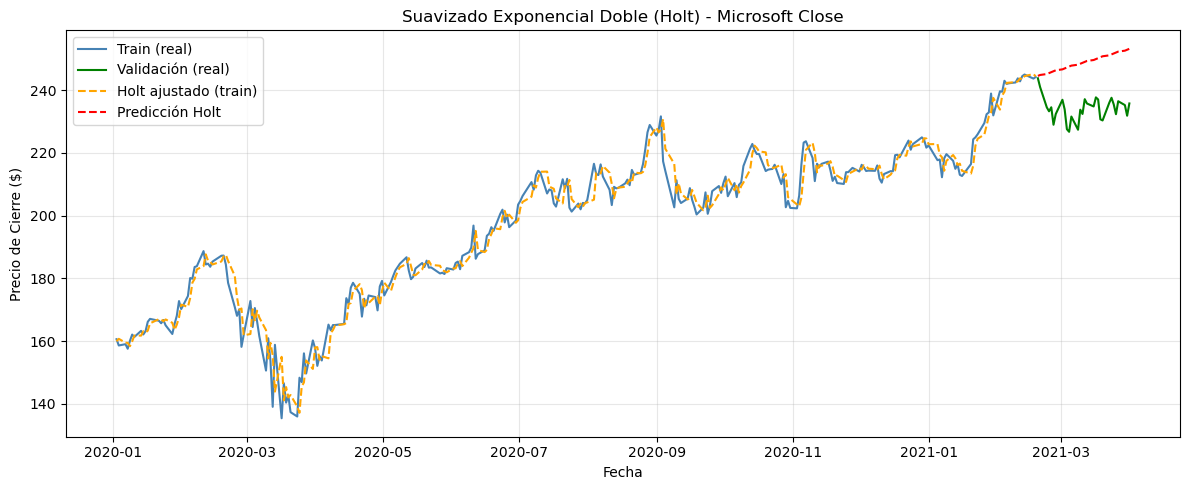

In [16]:
# Obtener los valores ajustados en el train
ajustados = modelo_ajustado.fittedvalues
ajustados.index = train.index
predicciones.index = val.index


# Gráfico
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(train.index, train, color='steelblue', label='Train (real)')
ax.plot(val.index, val, color='green', label='Validación (real)')
ax.plot(ajustados.index, ajustados, color='orange', linestyle='--', label='Holt ajustado (train)')
ax.plot(predicciones.index, predicciones, color='red', linestyle='--', label='Predicción Holt')

ax.set_title('Suavizado Exponencial Doble (Holt) - Microsoft Close')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de Cierre ($)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pregunta 4 ###
¿Qué tipo de suavizado exponencial se ha empleado y por qué?

***Respuesta:***

Pregunta 4 — Respuesta:

Se ha empleado el suavizado exponencial doble (Holt), configurado con tendencia aditiva 
y sin componente estacional (trend='add', seasonal=None). 
La elección se justifica por los análisis previos: la serie muestra una tendencia clara y sostenida 
pero no presenta estacionalidad apreciable ni en la inspección visual ni en la ACF.

En cuanto a los resultados, el modelo no predice bien el periodo de validación: 
la predicción sube linealmente, mientras los valores reales bajan. 

Pasamos ahora a entrenar un modelo autoregresivo para, de nuevo, predecir los 30 últimos valores. En este caso, si en puntos anteriores de esta práctica se hubiera determinado que la serie no es estacionaria, se debe convertir en estacionaria y comprobar que efectivamente lo es después de la transformación. Una vez que sea estacionaria, se ha de seleccionar en base a la función de autocorrelación (ACF) y/o la autocorrelación parcial (PACF) el orden adecuado del modelo autoregresivo (AR).

In [17]:
# Transformar la serie en estacionaria en caso de que no lo fuera

# Primera diferenciación

close_diff = df_2020['Close'].diff().dropna()


In [18]:
# Comprobación de estacionariedad

resultado_adf_diff = adfuller(close_diff)

print('ADF Statistic:', resultado_adf_diff[0])
print('p-value:', resultado_adf_diff[1])


ADF Statistic: -5.318637817274675
p-value: 5.009316788844223e-06


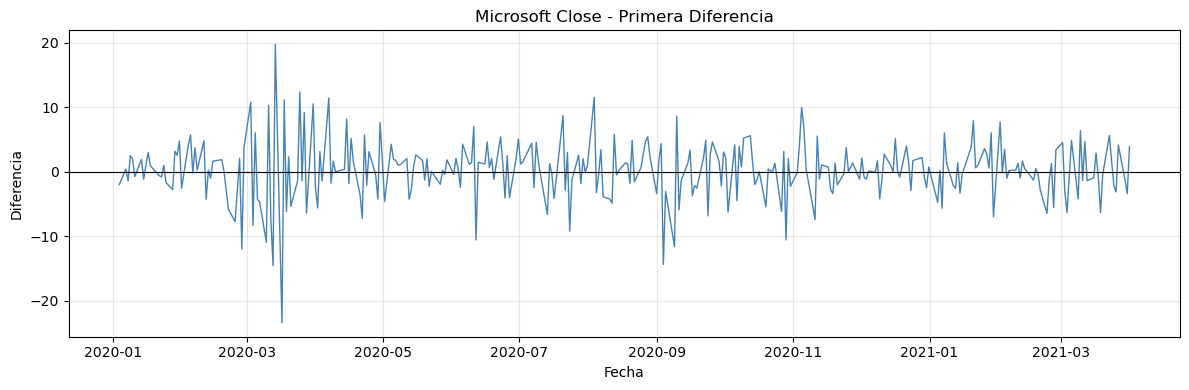

In [19]:
# Gráfico de la serie diferenciada
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(close_diff.index, close_diff, color='steelblue', linewidth=1)
ax.set_title('Microsoft Close - Primera Diferencia')
ax.set_xlabel('Fecha')
ax.set_ylabel('Diferencia')
ax.axhline(0, color='black', linewidth=0.8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

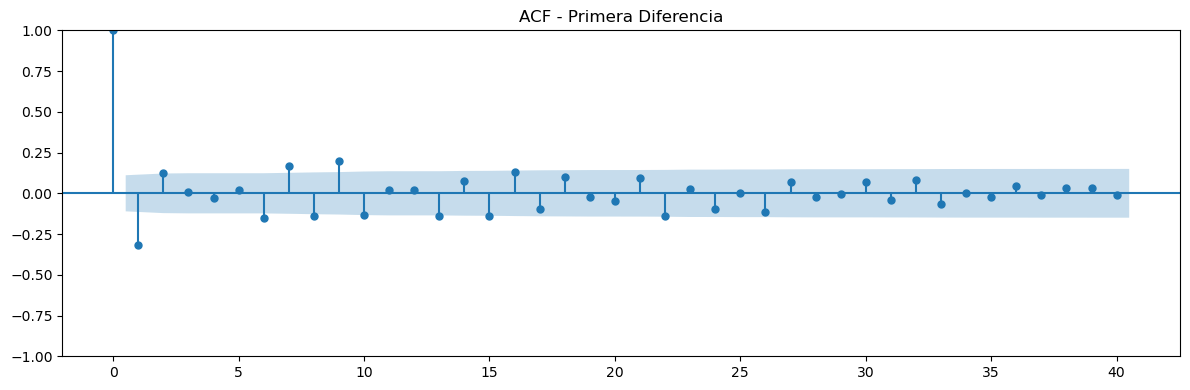

In [20]:
# Mostrar la función de autocorrelación y autocorrelación parcial
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(close_diff, lags=40, ax=ax, title='ACF - Primera Diferencia')
plt.tight_layout()
plt.show()

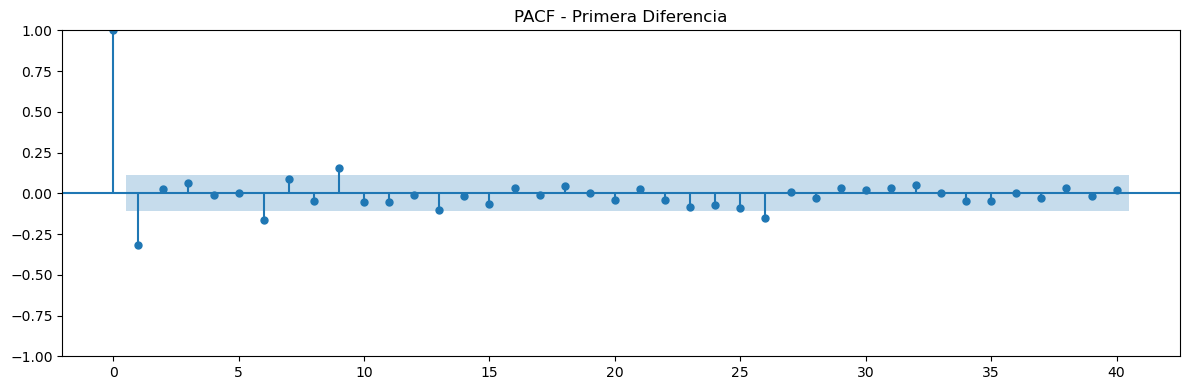

In [21]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(close_diff, lags=40, ax=ax, title='PACF - Primera Diferencia')
plt.tight_layout()
plt.show()

### Pregunta 5 ###
¿Cual es el orden del modelo autoregresivo que se ha seleccionado y por qué?

***Respuesta:***

Se ha seleccionado un modelo AR(2) porque tanto el punto 1 como el punto 2 de la PACF
aparecen fuera del intervalo de confianza. Aunque el punto 1 es el más destacado (~-0.30),
el  2 parece también superar apenas la banda, por lo que creo que incluirlo podria mejorar la capacidad explicativa 
del modelo sin añadir complejidad excesiva.

Una vez escogido el orden del modelo autorregresivo, pasamos a entrenar el modelo y a predecir los 30 últimos valores. Por tanto lo primero será, como en ejercicios anteriores, separar por un lado la serie original transformada en estacionaria en caso de que no lo fuera, y eso si, quitandole los últimos 30 puntos. Una vez entrenado, se ha de mostrar el resumen de los parametros del modelo, coeficientes y demás métricas habituales. A continuación, utilizar el modelo para predecir los últimos 30 valores y mostrarlos en un gráfico de lineas junto con la serie original. Antes de pintarlos, en caso de que la serie original haya sido transformada para convertirla en estacionaria, será necesario deshacer las transformaciones de los valores predichos y, ahora si, pintarla junto con los valores de la serie original.

In [22]:
# Separar en conjunto de entrenamiento y validación 

train_diff = close_diff.iloc[:-30]
val_diff = close_diff.iloc[-30:]

In [23]:
# Crear y ajustar el modelo autorregresivo del orden escogido
modelo_ar = AutoReg(train_diff, lags=2)
modelo_ar_ajustado = modelo_ar.fit()

<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [24]:
# Mostrar el resumen de los parametros y resultados del entrenamiento del modelo
print(modelo_ar_ajustado.summary())

                            AutoReg Model Results                             
Dep. Variable:                  Close   No. Observations:                  283
Model:                     AutoReg(2)   Log Likelihood                -814.736
Method:               Conditional MLE   S.D. of innovations              4.395
Date:                Mon, 29 Jun 2026   AIC                           1637.472
Time:                        23:40:46   BIC                           1652.026
Sample:                             2   HQIC                          1643.309
                                  283                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3856      0.264      1.461      0.144      -0.132       0.903
Close.L1      -0.3179      0.060     -5.335      0.000      -0.435      -0.201
Close.L2       0.0459      0.060      0.771      0.4

## Selección del orden del modelo AR

Inicialmente, observando la PACF de la serie diferenciada, se consideró incluir el lag 2 
al parecer rozar el intervalo de confianza, probando un modelo AR(2). 
Sin embargo, el resumen del modelo revela que el coeficiente de Close.L2 
tiene un p-valor de 0.441, muy por encima de 0.05, por lo que no es estadísticamente significativo.

Por esta razon se descartara el punto 2 y se optara mejor por un **AR(1)**, 
cuyo coeficiente (Close.L1) sí es muy significativo (p-value ≈ 0.000).

In [25]:
modelo_ar = AutoReg(train_diff, lags=1)
modelo_ar_ajustado = modelo_ar.fit()

print(modelo_ar_ajustado.summary())

                            AutoReg Model Results                             
Dep. Variable:                  Close   No. Observations:                  283
Model:                     AutoReg(1)   Log Likelihood                -817.444
Method:               Conditional MLE   S.D. of innovations              4.392
Date:                Mon, 29 Jun 2026   AIC                           1640.888
Time:                        23:40:46   BIC                           1651.813
Sample:                             1   HQIC                          1645.269
                                  283                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4016      0.262      1.532      0.125      -0.112       0.915
Close.L1      -0.3329      0.056     -5.932      0.000      -0.443      -0.223
                                    Roots           

<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [26]:
# Predecir los últimos 30 valores utilizando el modelo entrenado
pred_diff = modelo_ar_ajustado.predict(start=len(train_diff), end=len(train_diff)+29)
pred_diff.index = val_diff.index


<project folder> ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
<project folder> FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
<project folder> UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)


In [27]:
# Deshacer las transformaciones sobre los valores predichos último valor real del train original + acumulado de predicciones
ultimo_valor_train = df_2020['Close'].iloc[-31]  # último valor antes de validación
pred_original = ultimo_valor_train + pred_diff.cumsum()

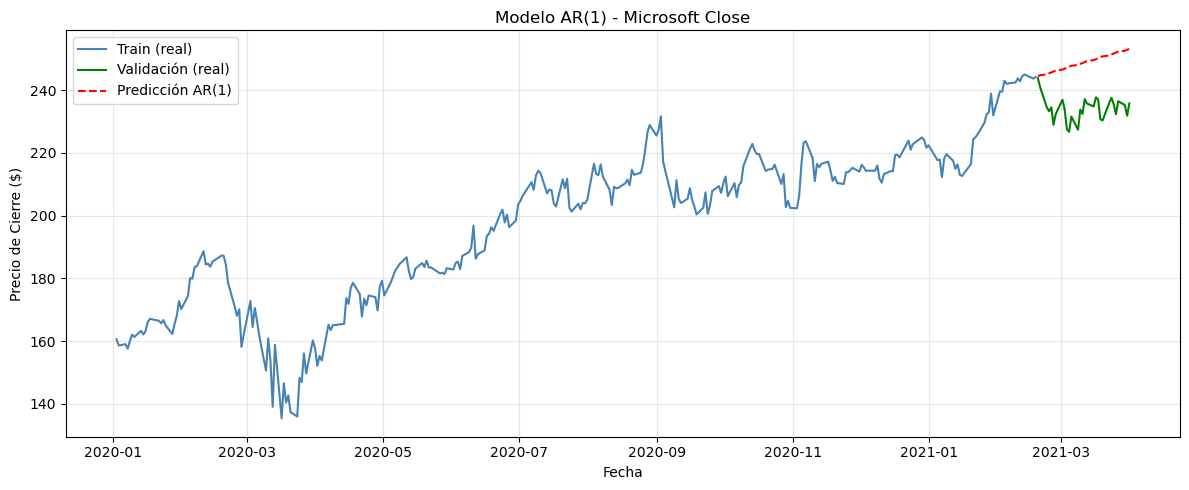

In [28]:
# Mostrar en gráfica la serie original y los valores predichos
train_original = df_2020['Close'].iloc[:-30]
val_original = df_2020['Close'].iloc[-30:]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_original.index, train_original, color='steelblue', label='Train (real)')
ax.plot(val_original.index, val_original, color='green', label='Validación (real)')
ax.plot(pred_original.index, pred_original, color='red', linestyle='--', label='Predicción AR(1)')
ax.set_title('Modelo AR(1) - Microsoft Close')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de Cierre ($)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

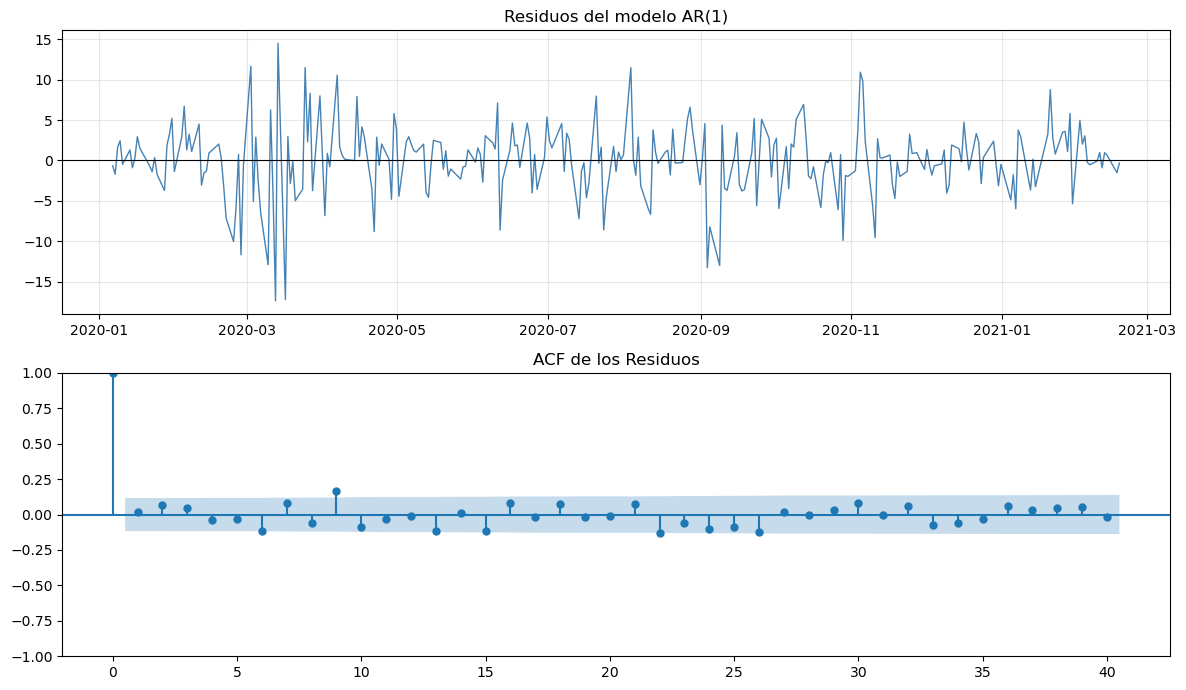

Media de residuos: -0.0
Desviación estándar: 4.3999


In [29]:
# Residuos del modelo
residuos = modelo_ar_ajustado.resid

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# Gráfico de residuos
axes[0].plot(residuos.index, residuos, color='steelblue', linewidth=1)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Residuos del modelo AR(1)')
axes[0].grid(True, alpha=0.3)

# ACF de residuos
plot_acf(residuos, lags=40, ax=axes[1], title='ACF de los Residuos')

plt.tight_layout()
plt.show()

print("Media de residuos:", round(residuos.mean(), 4))
print("Desviación estándar:", round(residuos.std(), 4))

### Pregunta 6 ###
A la vista de los resultados obtenidos en el entrenamiento del modelo, ¿qué podemos decir de los residuos y por tanto de la validez estadística del modelo?. En cuanto a la pinta que tiene el resultado final visualizado en el gráfico, ¿Qué conclusiones podemos sacar sobre el modelo? ¿es adecuado para predecir valores futuros de la serie? ¿De qué manera influye en esta valoración el hecho de que hayamos seleccionado para validar los últimos 30 puntos con respecto a la pinta que tendría si solo hubieran sido los últimos 20?

***Respuesta:***

Sobre los residuos: El modelo AR(1) presenta residuos con media prácticamente cero (-0.0) y desviación estándar de 4.40,lo que en términos
relativos sobre un precio de 230,  supone un error típico de 2% diario.

La ACF de los residuos muestra todos los retrasos dentro del intervalo de confianza, lo que indica que no queda autocorrelación estructural sin capturar. 

Sin embargo, se observa heterocedasticidad en el gráfico de residuos, con picos de mayor amplitud en el periodo de marzo 2020 (crash COVID), lo que viola parcialmente el supuesto de varianza constante.

Sobre la predicción visual: El modelo no es adecuado para predecir valores futuros de esta serie. 
Al igual que ocurrió con el suavizado exponencial, la predicción converge rápidamente hacia una línea 
casi recta ascendente, incapaz de capturar la volatilidad y los cambios de dirección reales de la serie. 

Sobre los 30 vs 20 puntos de validación:  Con 20 puntos la predicción arrancaría desde un valor más reciente 
y la divergencia acumulada sería mucho menor, por lo que visualmente parece que el modelo funciona mejor.(abajo dejo el ejemplo)

<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
<project folder> FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
<project folder> UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)


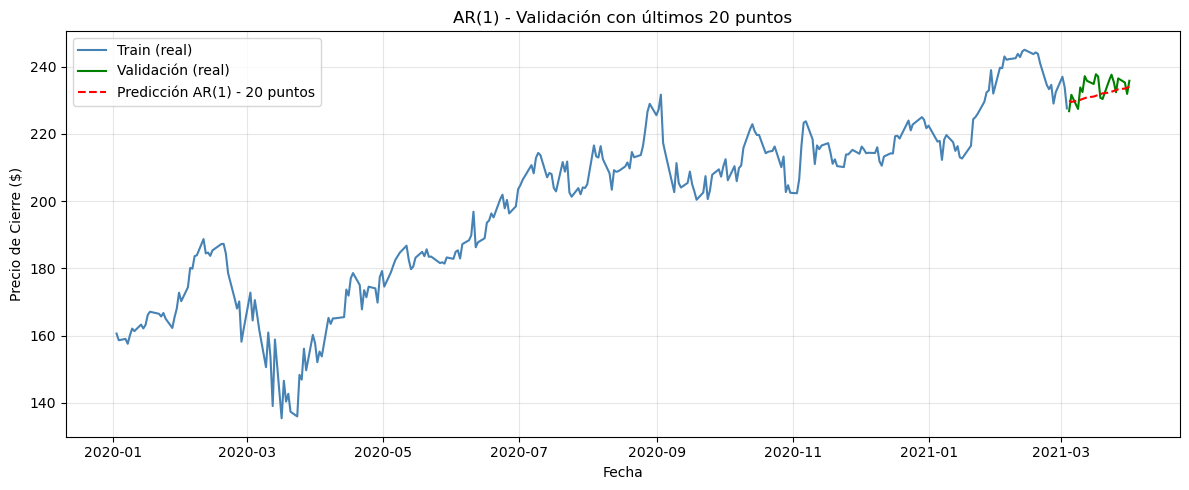

In [30]:
# Validación con últimos 20 puntos
train_20 = df_2020['Close'].iloc[:-20]
val_20 = df_2020['Close'].iloc[-20:]
train_diff_20 = close_diff.iloc[:-20]

modelo_ar_20 = AutoReg(train_diff_20, lags=1).fit()
pred_diff_20 = modelo_ar_20.predict(start=len(train_diff_20), end=len(train_diff_20)+19)
pred_diff_20.index = val_20.index

ultimo_valor_20 = df_2020['Close'].iloc[-21]
pred_original_20 = ultimo_valor_20 + pred_diff_20.cumsum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_20.index, train_20, color='steelblue', label='Train (real)')
ax.plot(val_20.index, val_20, color='green', label='Validación (real)')
ax.plot(pred_original_20.index, pred_original_20, color='red', linestyle='--', label='Predicción AR(1) - 20 puntos')
ax.set_title('AR(1) - Validación con últimos 20 puntos')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de Cierre ($)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Por último, el alumno debe optimizar el modelo, cambiando el orden de las componentes AR, I y MA del modelo ARIMA, hasta llegar a una combinación que mejore el anterior modelo y que pueda ser incluso utilizable para predecir valores futuros de la serie. Para ello puede optar por realizarlo de forma manual probando distintas combinaciones o mediante algún algoritmo automático que encuentre la mejor combinación de ordenes para el modelo.

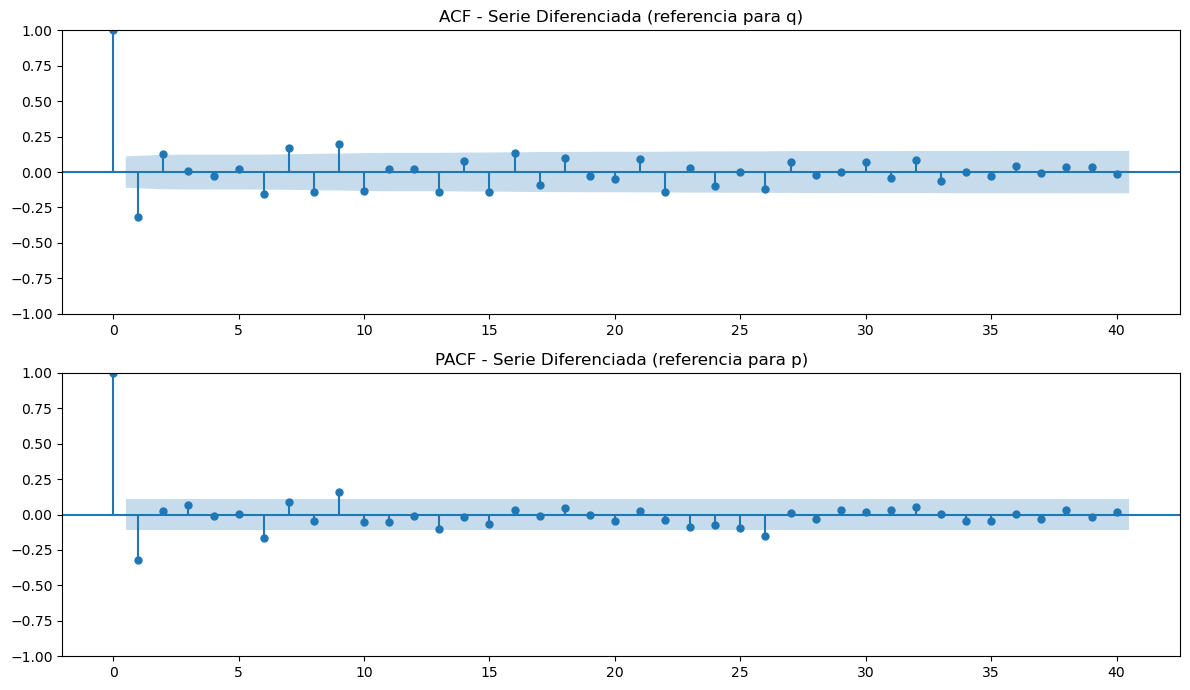

In [31]:
# Para el método manual, evaluar la ACF y PACF de la serie estacionaria (transformada si fuera necesario)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(close_diff, lags=40, ax=axes[0], title='ACF - Serie Diferenciada (referencia para q)')
plot_pacf(close_diff, lags=40, ax=axes[1], title='PACF - Serie Diferenciada (referencia para p)')
plt.tight_layout()
plt.show()

In [32]:
# Encontrar los ordenes p y q adecuados para las partes AR y MA

resultados = []
for p in [1, 2]:
    for q in [1, 2]:
        try:
            modelo = ARIMA(train_original, order=(p, 1, q)).fit()
            resultados.append((p, 1, q, round(modelo.aic, 2)))
            print(f"ARIMA({p},1,{q}) - AIC: {round(modelo.aic, 2)}")
        except Exception as e:
            print(f"ARIMA({p},1,{q}) - Error: {e}")

ARIMA(1,1,1) - AIC: 1647.8
ARIMA(1,1,2) - AIC: 1647.3
ARIMA(2,1,1) - AIC: 1648.74
ARIMA(2,1,2) - AIC: 1649.11


<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provide

In [33]:
# Aplicar el modelo ARIMA incluyendo los ordenes p y q, pero además incluyendo el orden de diferenciación d

# Entrenar ARIMA(1,1,2) - mejor AIC
modelo_arima = ARIMA(train_original, order=(1, 1, 2)).fit()
print(modelo_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                  284
Model:                 ARIMA(1, 1, 2)   Log Likelihood                -819.648
Date:                Mon, 29 Jun 2026   AIC                           1647.296
Time:                        23:40:46   BIC                           1661.878
Sample:                             0   HQIC                          1653.143
                                - 284                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0251      0.252      0.100      0.921      -0.470       0.520
ma.L1         -0.3385      0.249     -1.361      0.174      -0.826       0.149
ma.L2          0.1971      0.090      2.200      0.0

<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


## Refinamiento del modelo ARIMA

El summary del modelo ARIMA(1,1,2) revela que los coeficientes ar.L1 (p=0.921) 
y ma.L1 (p=0.174) no son estadísticamente significativos, siendo únicamente ma.L2 
el que aporta valor real al modelo.

Por esta razon, se prueba **ARIMA(0,1,2)**, eliminando 
la componente AR.

In [34]:
modelo_arima_012 = ARIMA(train_original, order=(0, 1, 2)).fit()
print(modelo_arima_012.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                  284
Model:                 ARIMA(0, 1, 2)   Log Likelihood                -819.652
Date:                Mon, 29 Jun 2026   AIC                           1645.304
Time:                        23:40:46   BIC                           1656.241
Sample:                             0   HQIC                          1649.690
                                - 284                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3145      0.041     -7.740      0.000      -0.394      -0.235
ma.L2          0.1899      0.045      4.220      0.000       0.102       0.278
sigma2        19.1864      1.203     15.949      0.0

<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
<project folder> ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


<project folder> ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
<project folder> FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


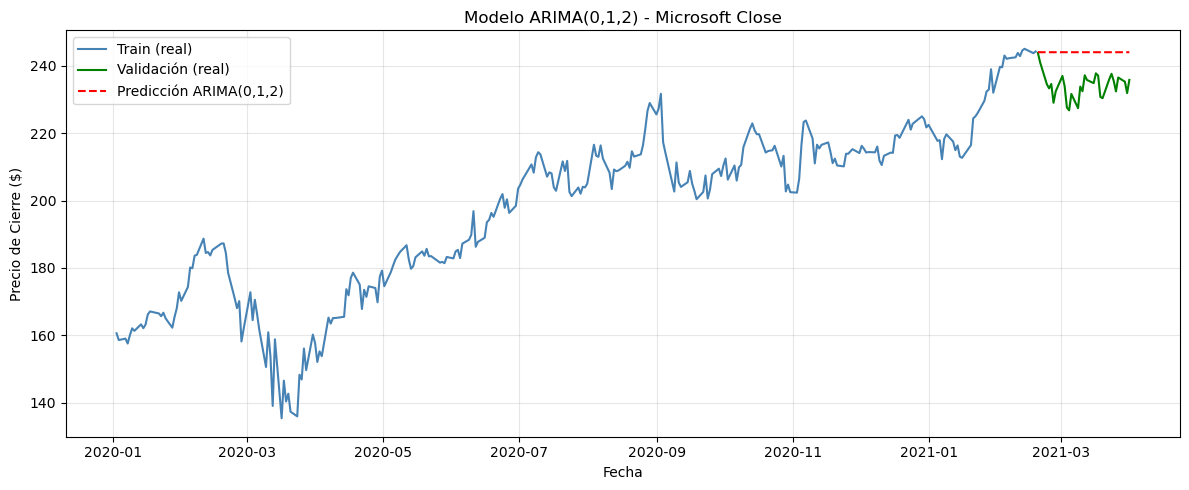

In [35]:
# Predecir y pintar los resultados como en puntos anteriores

pred_arima = modelo_arima_012.forecast(steps=30)
pred_arima.index = val_original.index

# Gráfico
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_original.index, train_original, color='steelblue', label='Train (real)')
ax.plot(val_original.index, val_original, color='green', label='Validación (real)')
ax.plot(pred_arima.index, pred_arima, color='red', linestyle='--', label='Predicción ARIMA(0,1,2)')
ax.set_title('Modelo ARIMA(0,1,2) - Microsoft Close')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de Cierre ($)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pregunta 7 ###
Hacer una interpretación libre del modelo entrenado y de los resultados obtenidos. ¿Sería utilizable para predicción de valores futuros de la serie temporal?

***Respuesta:***

Segun los resultados obtenidos, parece que el modelo ARIMA(0,1,2) representa la mejor combinación encontrada en este análisis,
con todos sus coeficientes estadísticamente significativos y el menor AIC de todos los modelos evaluados. 
 
Sin embargo, como ocurrió con el suavizado exponencial y el modelo AR(1), la predicción converge rápidamente hacia una línea plana,
sin capturar la volatilidad real de la serie.Pero no creo que sea un fallo del modelo en sí, 
sino que el valor de las acciones depende de factores que no podemos predecir. 

Creo que en este sentido, ningún modelo que solo observe el precio histórico puede anticipar estos shocks externos.

Por otra parte, creo que lo que sí puede asumir el modelo, y que entiendo tiene respaldo empírico, es que, generalmente, la serie 
tiende a revertir hacia cierto equilibrio, y los movimientos extremos se tienden a corregir y la volatilidad no es permanente. 
Esto explica el coeficiente negativo en ma.L1 (-0.31), una subida brusca tiende a ser parcialmente corregida en los días siguientes.
